In [17]:
# a. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.layers import Dense,Input
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("Dataset/ecg.csv", header = None).dropna()

In [3]:
X = df.iloc[:,:-1].values

In [4]:
Y = df.iloc[:,-1].values

In [5]:
print("Dataset shape:", X.shape)

Dataset shape: (4998, 140)


In [6]:
print("Dataset shape:", Y.shape)

Dataset shape: (4998,)


In [7]:
X_train,X_test,Y_train,Y_test = train_test_split(
    X,Y,test_size=0.2,random_state=42,stratify=Y
)

In [11]:
min_val = X_train.min()
max_val = X_train.max()

In [12]:
X_train = (X_train - min_val) / (max_val - min_val)
X_test = (X_test - min_val) / (max_val - min_val)

In [14]:
print(X_train.dtype)
print(X_test.dtype)

float64
float64


In [15]:
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

In [16]:
print(X_train.dtype)
print(X_test.dtype)

float32
float32


In [19]:
normal_train = X_train[Y_train==1]

In [20]:
print("\nNormal training samples:", normal_train.shape)


Normal training samples: (2335, 140)


In [21]:
input_dim = X_train.shape[1]

In [23]:
model = Sequential([
    Input(shape=(input_dim,)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),

    Dense(16, activation='relu'),
    Dense(32, activation='relu'),
    Dense(64, activation='relu'),
    Dense(input_dim,activation='sigmoid')
])

In [25]:
model.compile( optimizer = "adam", loss = "mse", metrics = ["mae"])

In [26]:
history = model.fit(
    normal_train,normal_train, epochs = 20, batch_size = 256, validation_split = 0.1, shuffle = True
)

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 136ms/step - loss: 0.0046 - mae: 0.0450 - val_loss: 0.0042 - val_mae: 0.0423
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0038 - mae: 0.0402 - val_loss: 0.0033 - val_mae: 0.0385
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0028 - mae: 0.0349 - val_loss: 0.0024 - val_mae: 0.0316
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0019 - mae: 0.0281 - val_loss: 0.0017 - val_mae: 0.0269
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0014 - mae: 0.0236 - val_loss: 0.0013 - val_mae: 0.0234
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0011 - mae: 0.0211 - val_loss: 0.0012 - val_mae: 0.0221
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0010 - mae: 0.0203 - val_loss: 0.0012 - val_mae: 0.0215
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 9.9740e-04 - mae: 0.0197 - val_loss: 0.0011 - val_mae: 0.0212
Epoch 9/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 9.8827e-04 - mae: 0.

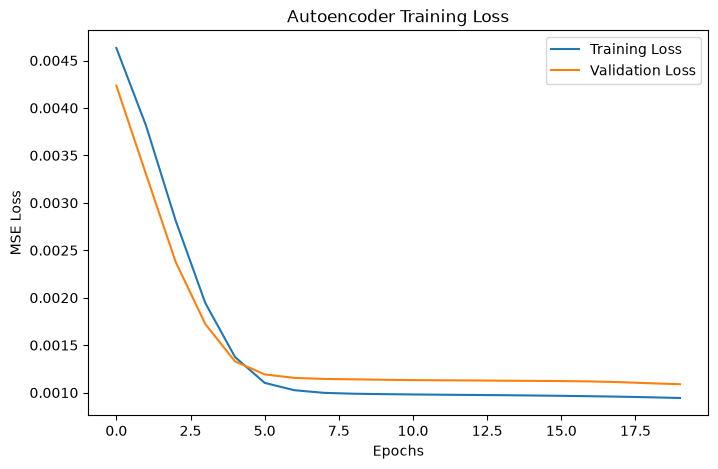

In [28]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Autoencoder Training Loss')
plt.legend()
plt.show()

In [37]:
train_recon = model.predict(normal_train, verbose=0)

In [38]:
train_err = np.mean(np.abs(normal_train-train_recon),axis=1)

In [39]:
threshold = np.mean(train_err)+ np.std(train_err)

In [40]:
print("\nAnomaly Threshold:", threshold)


Anomaly Threshold: 0.02956687


In [41]:
test_recon = model.predict(X_test, verbose=0)

In [42]:
test_err = np.mean(np.abs(X_test-test_recon),axis=1)

In [43]:
predicted = (test_err<=threshold).astype(int)

In [45]:
accuracy = np.mean(predicted == Y_test) * 100
print("\nTest Accuracy:", accuracy, "%")



Test Accuracy: 93.5 %


In [48]:
print("\nActual vs Predicted")

for i in range(10):
    if Y_test[i]==1:
        actual = "Normal"
    else:
        actual = "Abnormal"

    if predicted[i] == 1:
        result = "Normal"
    else:
        result = "Abnormal"
    print(f"\nActual: {actual}, Predicted: {result}, Error: {test_err[i]}")


Actual vs Predicted

Actual: Abnormal, Predicted: Abnormal, Error: 0.046644940972328186

Actual: Abnormal, Predicted: Abnormal, Error: 0.04554978013038635

Actual: Normal, Predicted: Abnormal, Error: 0.06820464879274368

Actual: Normal, Predicted: Normal, Error: 0.02245888113975525

Actual: Normal, Predicted: Abnormal, Error: 0.04885721951723099

Actual: Normal, Predicted: Normal, Error: 0.017534323036670685

Actual: Abnormal, Predicted: Abnormal, Error: 0.044987455010414124

Actual: Abnormal, Predicted: Abnormal, Error: 0.047186434268951416

Actual: Abnormal, Predicted: Abnormal, Error: 0.04224615916609764

Actual: Normal, Predicted: Normal, Error: 0.01771298050880432


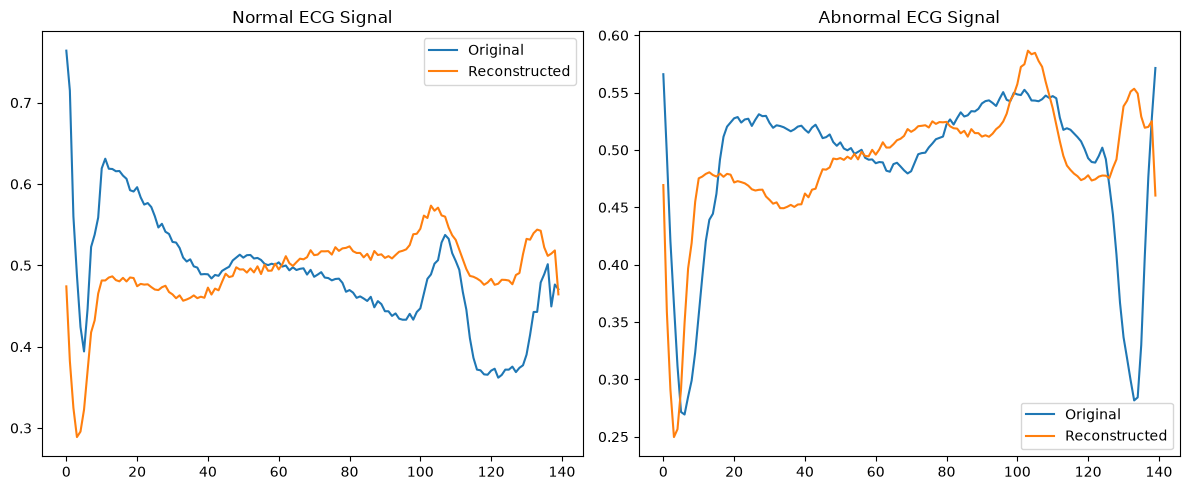

In [50]:
normal_idx = np.where(Y_test == 1)[0][0]
abnormal_idx = np.where(Y_test == 0)[0][0]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(X_test[normal_idx], label='Original')
plt.plot(test_recon[normal_idx], label='Reconstructed')
plt.title('Normal ECG Signal')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(X_test[abnormal_idx], label='Original')
plt.plot(test_recon[abnormal_idx], label='Reconstructed')
plt.title('Abnormal ECG Signal')
plt.legend()

plt.tight_layout()
plt.show()

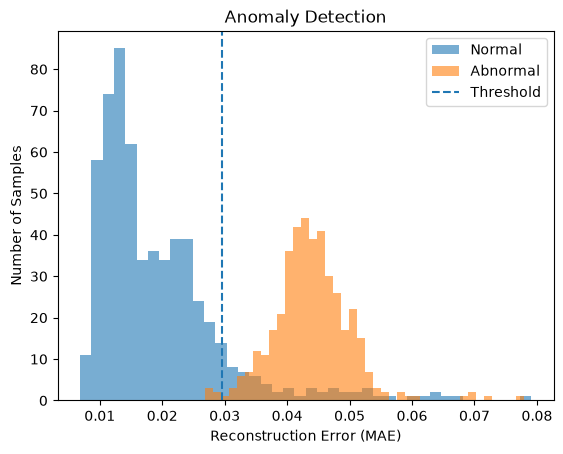

In [53]:
# 9. Display reconstruction error distribution
plt.hist(test_err[Y_test == 1], bins=40, alpha=0.6, label='Normal')
plt.hist(test_err[Y_test == 0], bins=40, alpha=0.6, label='Abnormal')
plt.axvline(threshold, linestyle='--', label='Threshold')

plt.xlabel('Reconstruction Error (MAE)')
plt.ylabel('Number of Samples')
plt.title('Anomaly Detection')
plt.legend()
plt.show()